In [2]:

import numpy as np
import matplotlib.pyplot as plt


In [3]:

def reward(state, action):
    if state==0 and state == 1:
        return 1
    elif state == 3 and action ==1:
        return 5
    else:
        return 0
    
    
def transition_prob(state, action, next_state):
    if state==0 and action == 1 and next_state==1:
        return 1
    elif state == 3 and action == 0 and next_state ==2:
        return 1
    elif state == next_state:
        return 0.5
    else:
        return 0
    



Iteration 1
[[0.  0. ]
 [0.  0. ]
 [0.  0. ]
 [0.  2.5]]


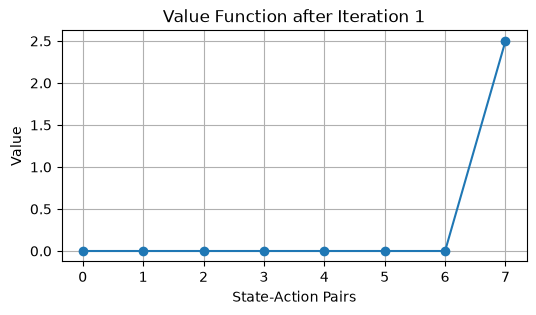


Iteration 2
[[0.    0.   ]
 [0.    0.   ]
 [0.    0.   ]
 [1.125 3.625]]


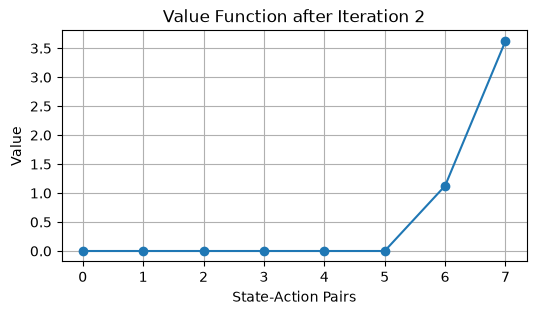


Iteration 3
[[0.      0.     ]
 [0.      0.     ]
 [0.      0.     ]
 [1.63125 4.13125]]


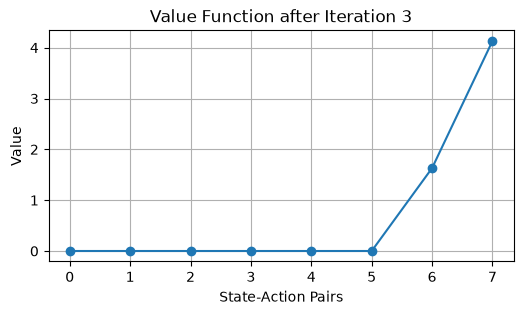


Iteration 4
[[0.        0.       ]
 [0.        0.       ]
 [0.        0.       ]
 [1.8590625 4.3590625]]


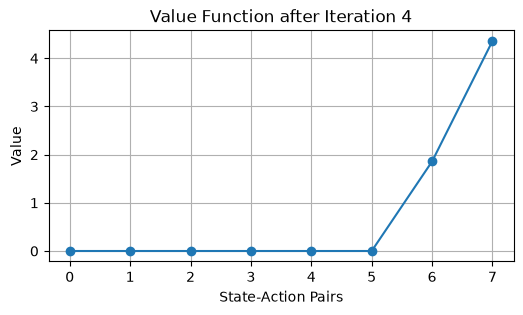


Iteration 5
[[0.         0.        ]
 [0.         0.        ]
 [0.         0.        ]
 [1.96157813 4.46157812]]


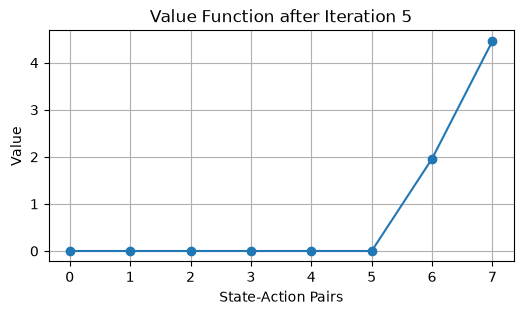


Optimal Value Function
[[0.         0.        ]
 [0.         0.        ]
 [0.         0.        ]
 [1.96157813 4.46157812]]


In [ ]:
def bellman_eqn(value, gamma):
    new_value = np.zeros_like(value)
    for state in range(value.shape[0]):
        for action in range(value.shape[1]):
            action_value = 0
            for next_state in range(value.shape[0]):
                action_value += (
                    transition_prob(state, action, next_state)
                    * (
                        reward(state, action)
                        + gamma * np.max(value[next_state])
                    )
                )
            new_value[state, action] = action_value
    return new_value
def main():
    # 4 states, 2 actions
    value = np.zeros((4, 2))
    gamma = 0.9
    iterations = 5
    for i in range(iterations):
        value = bellman_eqn(value, gamma)
        print(f"\nIteration {i+1}")
        print(value)
        plt.figure(figsize=(6, 3))
        plt.plot(value.flatten(), marker='o')
        plt.title(f"Value Function after Iteration {i+1}")
        plt.xlabel("State-Action Pairs")
        plt.ylabel("Value")
        plt.grid(True)
        plt.show()
    print("\nOptimal Value Function")
    print(value)


if __name__ == "__main__":
    main()